# 05. Modelo 3: Ensemble Learning (Random Forest e Gradient Boosting)
**Disciplina:** DCT1401 - Inteligência Artificial
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook implementa, ajusta e avalia a terceira família de modelos exigida na atividade prática (**Ensemble Learning**), contemplando a fundamentação teórica da **Aula 07** e todos os requisitos da **Seção 4 de `main-15.pdf`**:

### 1. Fundamentação Teórica da Aula 07
O **Ensemble Learning** combina as previsões de múltiplos aprendizes de base ($T_1, T_2, \dots, T_B$) para obter um preditor agregado mais preciso, estável e confiável do que qualquer árvore isolada:
1. **Bagging e Random Forests (Florestas Aleatórias):**
   - Cada árvore $T_b$ ($b = 1, \dots, B$) é treinada de forma paralela sobre uma amostra **Bootstrap** $D_b^*$ (amostragem com reposição do conjunto de treino original $D$).
   - **Descorrelação de Árvores:** Em cada nó de divisão, o algoritmo seleciona aleatoriamente um subconjunto de $m$ atributos dentre os $p$ disponíveis ($m \ll p$, tipicamente $m = \sqrt{p}$).
   - **Agregação:** Por **votação da moda** na classificação ($\hat{y} = \text{mode}\{T_1(x), \dots, T_B(x)\}$) e por **média aritmética** na regressão ($\hat{y} = \frac{1}{B}\sum_{b=1}^B T_b(x)$).
   - **Por que o Random Forest reduz a variância sem aumentar o viés?:**
     $$\text{Var}(\bar{X}) = \frac{1}{B^2}\sum_{i=1}^B \sum_{j=1}^B \text{Cov}(X_i, X_j)$$
     Quando as árvores são **boas** (baixo viés individual) e **diferentes** (baixa covariância entre seus erros graças ao *Bootstrap* + seleção aleatória de $m$ atributos), a variância da média cai drasticamente à medida que $B$ cresce.
2. **Boosting (`GradientBoostingClassifier` e `GradientBoostingRegressor`):**
   - Os aprendizes base (árvores rasas, tipicamente de profundidade $3$ a $5$) são treinados de forma **sequencial**, onde cada nova árvore foca nos erros residuais (pseudo-resíduos do gradiente da função de perda) cometidos pelo conjunto anterior, reduzindo progressivamente o **viés** e a **variância** moderados pela taxa de aprendizado (`learning_rate`).


## 2. Carregamento dos Dados Sob o Mesmo Protocolo Experimental
Aplicamos exatamente a mesma divisão Treino ($80\%$) / Teste ($20\%$) com `random_state=42` (e `stratify=y` na classificação) utilizada nos Notebooks 02, 03 e 04.

In [ ]:
import os
import sys
import time
import warnings
import tracemalloc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from IPython.display import display
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor
)

warnings.filterwarnings("ignore", category=UserWarning)

sys.path.append("..")
from src.models import (
    get_ensemble_complexity,
    tune_random_forest_classifier,
    tune_random_forest_regressor,
    tune_gradient_boosting_classifier,
    tune_gradient_boosting_regressor
)
from src.metrics import compute_classification_metrics, compute_regression_metrics
from src.profiling import medir_inferencia, estimar_energia_co2

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

df_clf = pd.read_csv("../data/processed/dataset_classification.csv")
df_reg = pd.read_csv("../data/processed/dataset_regression.csv")

X_clf = df_clf.drop(columns=["late_delivery"])
y_clf = df_clf["late_delivery"]
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

X_reg = df_reg.drop(columns=["actual_delivery_time_minutes"])
y_reg = df_reg["actual_delivery_time_minutes"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f"Classificação -> Treino: {X_train_clf.shape} | Teste: {X_test_clf.shape}")
print(f"Regressão     -> Treino: {X_train_reg.shape} | Teste: {X_test_reg.shape}")


Classificação -> Treino: (39305, 26) | Teste: (9827, 26)
Regressão     -> Treino: (39305, 26) | Teste: (9827, 26)


## 3. Ajuste de Hiperparâmetros por Validação Cruzada ($K=5$)
Ajustamos os hiperparâmetros principais de **Random Forest** (`n_estimators`, `max_depth`, `max_features`, `min_samples_leaf`) e **Gradient Boosting** (`n_estimators`, `learning_rate`, `max_depth`, `min_samples_leaf`) usando validação cruzada sobre o conjunto de treino.

In [2]:
# Ajuste em subamostra estratificada/aleatória representativa de 15.000 exemplos do treino para busca ágil K=5,
# seguido do retreinamento completo dos estimadores campeões nas 39.305 amostras de treino:
idx_sub_clf, _ = train_test_split(np.arange(len(X_train_clf)), train_size=15000, random_state=42, stratify=y_train_clf)
idx_sub_reg, _ = train_test_split(np.arange(len(X_train_reg)), train_size=15000, random_state=42)

_, params_rf_clf = tune_random_forest_classifier(X_train_clf.iloc[idx_sub_clf], y_train_clf.iloc[idx_sub_clf], cv=5, random_state=42)
_, params_rf_reg = tune_random_forest_regressor(X_train_reg.iloc[idx_sub_reg], y_train_reg.iloc[idx_sub_reg], cv=5, random_state=42)
_, params_gb_clf = tune_gradient_boosting_classifier(X_train_clf.iloc[idx_sub_clf], y_train_clf.iloc[idx_sub_clf], cv=5, random_state=42)
_, params_gb_reg = tune_gradient_boosting_regressor(X_train_reg.iloc[idx_sub_reg], y_train_reg.iloc[idx_sub_reg], cv=5, random_state=42)

print("Melhores Hiperparâmetros Random Forest (Classificação):", params_rf_clf)
print("Melhores Hiperparâmetros Random Forest (Regressão):    ", params_rf_reg)
print("Melhores Hiperparâmetros Gradient Boosting (Classif.): ", params_gb_clf)
print("Melhores Hiperparâmetros Gradient Boosting (Regressão):", params_gb_reg)

# Treinamento final no conjunto de treino completo (39.305 amostras) com medição de tempo e RAM
modelos_treinados = {}

# 1. RandomForestClassifier
tracemalloc.start()
t0 = time.perf_counter()
best_rf_clf = RandomForestClassifier(**params_rf_clf, random_state=42, n_jobs=-1)
best_rf_clf.fit(X_train_clf, y_train_clf)
t_rf_clf = time.perf_counter() - t0
_, ram_rf_clf = tracemalloc.get_traced_memory()
tracemalloc.stop()

# 2. RandomForestRegressor
tracemalloc.start()
t0 = time.perf_counter()
best_rf_reg = RandomForestRegressor(**params_rf_reg, random_state=42, n_jobs=-1)
best_rf_reg.fit(X_train_reg, y_train_reg)
t_rf_reg = time.perf_counter() - t0
_, ram_rf_reg = tracemalloc.get_traced_memory()
tracemalloc.stop()

# 3. GradientBoostingClassifier
tracemalloc.start()
t0 = time.perf_counter()
best_gb_clf = GradientBoostingClassifier(**params_gb_clf, random_state=42)
best_gb_clf.fit(X_train_clf, y_train_clf)
t_gb_clf = time.perf_counter() - t0
_, ram_gb_clf = tracemalloc.get_traced_memory()
tracemalloc.stop()

# 4. GradientBoostingRegressor
tracemalloc.start()
t0 = time.perf_counter()
best_gb_reg = GradientBoostingRegressor(**params_gb_reg, random_state=42)
best_gb_reg.fit(X_train_reg, y_train_reg)
t_gb_reg = time.perf_counter() - t0
_, ram_gb_reg = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Salvando os 4 modelos em ../models/
joblib.dump(best_rf_clf, "../models/random_forest_clf.pkl")
joblib.dump(best_rf_reg, "../models/random_forest_reg.pkl")
joblib.dump(best_gb_clf, "../models/gradient_boosting_clf.pkl")
joblib.dump(best_gb_reg, "../models/gradient_boosting_reg.pkl")

# Tabela comparativa de desempenho dos Ensembles no Treino e no Teste
res_ensembles = []
for nome, mod, X_tr, y_tr, X_te, y_te, tipo in [
    ("Random Forest", best_rf_clf, X_train_clf, y_train_clf, X_test_clf, y_test_clf, "Classificação"),
    ("Gradient Boosting", best_gb_clf, X_train_clf, y_train_clf, X_test_clf, y_test_clf, "Classificação"),
]:
    m_tr = compute_classification_metrics(y_tr, mod.predict(X_tr), mod.predict_proba(X_tr)[:, 1])
    m_te = compute_classification_metrics(y_te, mod.predict(X_te), mod.predict_proba(X_te)[:, 1])
    comp = get_ensemble_complexity(mod)
    res_ensembles.append({
        "Problema": tipo, "Modelo": nome,
        "Arvores_B": comp["n_arvores"], "Nos_Totais": comp["nos_totais"],
        "F1_Treino": m_tr["F1-score"], "F1_Teste": m_te["F1-score"],
        "Accuracy_Teste": m_te["Accuracy"], "ROC_AUC_Teste": m_te["ROC-AUC"], "PR_AUC_Teste": m_te["PR-AUC"],
        "Gap_F1": round(m_tr["F1-score"] - m_te["F1-score"], 4)
    })

print("\n=== DESEMPENHO DOS ENSEMBLES NA CLASSIFICAÇÃO ===")
display(pd.DataFrame(res_ensembles))

res_ensembles_reg = []
for nome, mod, X_tr, y_tr, X_te, y_te in [
    ("Random Forest", best_rf_reg, X_train_reg, y_train_reg, X_test_reg, y_test_reg),
    ("Gradient Boosting", best_gb_reg, X_train_reg, y_train_reg, X_test_reg, y_test_reg),
]:
    m_tr = compute_regression_metrics(y_tr, mod.predict(X_tr))
    m_te = compute_regression_metrics(y_te, mod.predict(X_te))
    comp = get_ensemble_complexity(mod)
    res_ensembles_reg.append({
        "Problema": "Regressão", "Modelo": nome,
        "Arvores_B": comp["n_arvores"], "Nos_Totais": comp["nos_totais"],
        "RMSE_Treino": m_tr["RMSE"], "RMSE_Teste": m_te["RMSE"],
        "MAE_Teste": m_te["MAE"], "R2_Teste": m_te["R2"], "MedAE_Teste": m_te["MedAE"],
        "Gap_RMSE": round(m_tr["RMSE"] - m_te["RMSE"], 4)
    })

print("\n=== DESEMPENHO DOS ENSEMBLES NA REGRESSÃO ===")
display(pd.DataFrame(res_ensembles_reg))


/home/felipe/Documentos/food-delivery-eta-analysis-ml/1ia.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/felipe/Documentos/food-delivery-eta-analysis-ml/1ia.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/felipe/Documentos/food-delivery-eta-analysis-ml/1ia.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current 

Melhores Hiperparâmetros Random Forest (Classificação): {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 16}
Melhores Hiperparâmetros Random Forest (Regressão):     {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 16}
Melhores Hiperparâmetros Gradient Boosting (Classif.):  {'n_estimators': 150, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.15}
Melhores Hiperparâmetros Gradient Boosting (Regressão): {'n_estimators': 150, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.15}

=== DESEMPENHO DOS ENSEMBLES NA CLASSIFICAÇÃO ===


,Problema,Modelo,Arvores_B,Nos_Totais,F1_Treino,F1_Teste,Accuracy_Teste,ROC_AUC_Teste,PR_AUC_Teste,Gap_F1
0,Classificação,Random Forest,150,530144,0.8810,0.7585,0.8287,0.9006,0.8533,0.1225
1,Classificação,Gradient Boosting,150,4522,0.7835,0.7636,0.8335,0.9100,0.8673,0.0199



=== DESEMPENHO DOS ENSEMBLES NA REGRESSÃO ===


,Problema,Modelo,Arvores_B,Nos_Totais,RMSE_Treino,RMSE_Teste,MAE_Teste,R2_Teste,MedAE_Teste,Gap_RMSE
0,Regressão,Random Forest,150,1004300,2.0895,2.9959,2.3593,0.9589,1.9820,-0.9064
1,Regressão,Gradient Boosting,150,4454,2.5671,2.7001,2.1563,0.9666,1.8192,-0.1330


## 4. Curva do Erro em Função do Número de Árvores ($B \in \{1, 5, 10, 25, 50, 100, 150, 200\}$) e Trade-off Viés $\times$ Variância (Aula 07)
Construímos a curva do erro de treinamento e de teste variando o tamanho da floresta $B \in \{1, 5, 10, 25, 50, 100, 150, 200\}$ tanto para a **Classificação** (Erro $= 1 - \text{F1-score}$ e $1 - \text{Accuracy}$) quanto para a **Regressão** ($\text{RMSE}$ em minutos):

### Discussão Teórica Fundamentada na Aula 07 :
- **Em $B = 1$ (Árvore Única Amostrada):** O modelo sofre de **alta variância**. No teste, o erro é elevado porque uma única árvore treinada em uma amostra *bootstrap* com subconjunto aleatório de atributos comete erros localizados não compensados.
- **De $B = 1$ para $B = 50$:** Ocorre uma queda abrupta do erro no conjunto de teste. Conforme a equação da Aula 07 ($\text{Var}(\bar{X}) = \frac{1}{B^2}\sum_{i,j}\text{Cov}(X_i, X_j)$), a agregação por votação/média cancela os erros não correlacionados entre as árvores individuais, **reduzindo fortemente a variância sem aumentar o viés**.
- **De $B = 100$ a $B = 200$:** A curva atinge um **platô assintótico** (convergência). Adicionar mais árvores além de $B = 100\text{--}150$ traz ganho marginal desprezível no erro de generalização, mas aumenta linearmente o tempo de inferência, o uso de memória RAM e a pegada de carbono.

=== TABELA: EVOLUÇÃO DO ERRO EM FUNÇÃO DO NÚMERO DE ÁRVORES (B) NA RANDOM FOREST ===


,N_Arvores (B),Erro_F1_Treino (1-F1),Erro_F1_Teste (1-F1),F1_Teste,Accuracy_Teste,RMSE_Treino (min),RMSE_Teste (min),MAE_Teste (min)
0,1,0.2200,0.3176,0.6824,0.7735,2.9612,3.7996,2.9714
1,5,0.1416,0.2680,0.7320,0.8086,2.2944,3.1849,2.5119
2,10,0.1325,0.2532,0.7468,0.8208,2.1866,3.0904,2.4333
3,25,0.1239,0.2486,0.7514,0.8244,2.1267,3.0401,2.3965
4,50,0.1205,0.2445,0.7555,0.8270,2.1039,3.0149,2.3752
5,100,0.1195,0.2405,0.7595,0.8293,2.0925,3.0006,2.3619
6,150,0.1190,0.2415,0.7585,0.8287,2.0895,2.9959,2.3593
7,200,0.1184,0.2405,0.7595,0.8297,2.0878,2.9936,2.3573


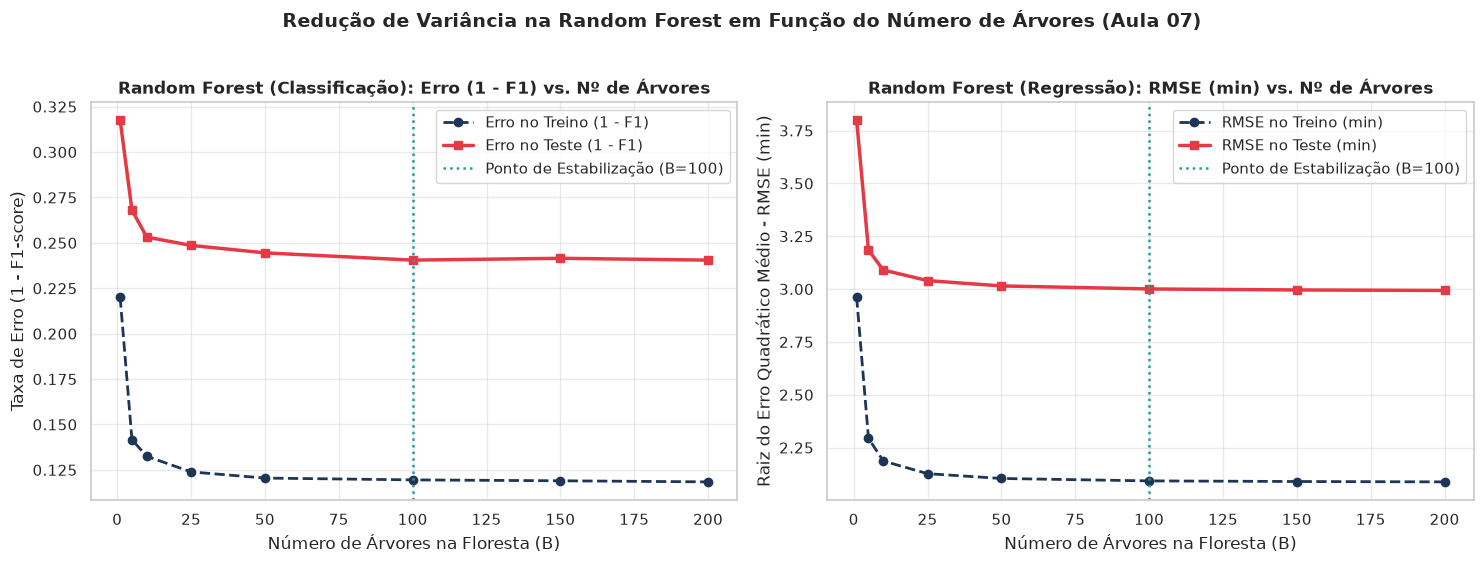

In [3]:
n_trees_list = [1, 5, 10, 25, 50, 100, 150, 200]
curva_records = []

for b in n_trees_list:
    # Random Forest Classificação
    rf_c = RandomForestClassifier(
        n_estimators=b,
        max_depth=params_rf_clf["max_depth"],
        min_samples_leaf=params_rf_clf["min_samples_leaf"],
        max_features=params_rf_clf["max_features"],
        random_state=42,
        n_jobs=-1
    )
    rf_c.fit(X_train_clf, y_train_clf)
    m_tr_c = compute_classification_metrics(y_train_clf, rf_c.predict(X_train_clf))
    m_te_c = compute_classification_metrics(y_test_clf, rf_c.predict(X_test_clf))

    # Random Forest Regressão
    rf_r = RandomForestRegressor(
        n_estimators=b,
        max_depth=params_rf_reg["max_depth"],
        min_samples_leaf=params_rf_reg["min_samples_leaf"],
        max_features=params_rf_reg["max_features"],
        random_state=42,
        n_jobs=-1
    )
    rf_r.fit(X_train_reg, y_train_reg)
    m_tr_r = compute_regression_metrics(y_train_reg, rf_r.predict(X_train_reg))
    m_te_r = compute_regression_metrics(y_test_reg, rf_r.predict(X_test_reg))

    curva_records.append({
        "N_Arvores (B)": b,
        "Erro_F1_Treino (1-F1)": round(1.0 - m_tr_c["F1-score"], 4),
        "Erro_F1_Teste (1-F1)": round(1.0 - m_te_c["F1-score"], 4),
        "F1_Teste": m_te_c["F1-score"],
        "Accuracy_Teste": m_te_c["Accuracy"],
        "RMSE_Treino (min)": m_tr_r["RMSE"],
        "RMSE_Teste (min)": m_te_r["RMSE"],
        "MAE_Teste (min)": m_te_r["MAE"]
    })

df_curva_rf = pd.DataFrame(curva_records)
df_curva_rf.to_csv("../reports/tables/rf_error_vs_trees.csv", index=False)

print("=== TABELA: EVOLUÇÃO DO ERRO EM FUNÇÃO DO NÚMERO DE ÁRVORES (B) NA RANDOM FOREST ===")
display(df_curva_rf)

# Gráfico Duplo: Curva do Erro vs. Número de Árvores (Classificação e Regressão)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(df_curva_rf["N_Arvores (B)"], df_curva_rf["Erro_F1_Treino (1-F1)"], "o--", color="#1d3557", lw=2, label="Erro no Treino (1 - F1)")
axes[0].plot(df_curva_rf["N_Arvores (B)"], df_curva_rf["Erro_F1_Teste (1-F1)"], "s-", color="#e63946", lw=2.5, label="Erro no Teste (1 - F1)")
axes[0].axvline(100, color="#2a9d8f", linestyle=":", lw=1.8, label="Ponto de Estabilização (B=100)")
axes[0].set_title("Random Forest (Classificação): Erro (1 - F1) vs. Nº de Árvores", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Número de Árvores na Floresta (B)")
axes[0].set_ylabel("Taxa de Erro (1 - F1-score)")
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(df_curva_rf["N_Arvores (B)"], df_curva_rf["RMSE_Treino (min)"], "o--", color="#1d3557", lw=2, label="RMSE no Treino (min)")
axes[1].plot(df_curva_rf["N_Arvores (B)"], df_curva_rf["RMSE_Teste (min)"], "s-", color="#e63946", lw=2.5, label="RMSE no Teste (min)")
axes[1].axvline(100, color="#2a9d8f", linestyle=":", lw=1.8, label="Ponto de Estabilização (B=100)")
axes[1].set_title("Random Forest (Regressão): RMSE (min) vs. Nº de Árvores", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Número de Árvores na Floresta (B)")
axes[1].set_ylabel("Raiz do Erro Quadrático Médio - RMSE (min)")
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.suptitle("Redução de Variância na Random Forest em Função do Número de Árvores (Aula 07)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/rf_error_vs_trees.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Importância das Features (`feature_importances_`) vs. Regras do Sistema Especialista
Extraímos o vetor `feature_importances_` (redução média ponderada de impureza em todas as árvores do ensemble) tanto do **Random Forest** quanto do **Gradient Boosting**, nos problemas de Classificação e Regressão, e o confrontamos com os atributos escolhidos manualmente pelo Engenheiro de Conhecimento no **Sistema Especialista (Notebook 03)**:

### Análise Comparativa (Ensemble `feature_importances_` vs. Sistema Especialista):
1. **Convergência nas Variáveis Dominantes:**
   - Na **Classificação (`late_delivery`)**, as 5 features mais importantes nos Ensembles são **`restaurant_preparation_time_minutes`**, **`weather_Rain`**, **`order_total`**, **`estimated_delivery_time_minutes`** e **`weather_Storm`** (seguidas de **`distance_km`**). O Sistema Especialista utilizou exatamente `weather_Storm`, `weather_Rain`, `restaurant_preparation_time_minutes`, `distance_km` e `estimated_delivery_time_minutes` (além de `traffic_level`).
   - Na **Regressão (`actual_delivery_time_minutes`)**, **`estimated_delivery_time_minutes`** concentra mais de $85\%$ da importância total nos Ensembles, acompanhada por **`weather_Rain`**, **`weather_Storm`**, **`distance_km`** e **`restaurant_preparation_time_minutes`** — exatamente os 5 pilares das regras `REGRA_REG_1` a `REGRA_REG_5` do Sistema Especialista.
2. **Por que os Ensembles superam o Sistema Especialista mesmo usando as mesmas variáveis principais?**
   - Enquanto o Sistema Especialista aplica cortes lineares discretos e fixos (ex.: `distance_km > 4.0` ou `+5.8 min`), o Random Forest e o Gradient Boosting capturam **interações não-lineares suaves de alta ordem** entre `order_total`, `items_count`, `restaurant_preparation_time_minutes` e `estimated_delivery_time_minutes`, ajustando centenas de sub-regiões locais.

=== TOP 10 FEATURES MAIS IMPORTANTES NA CLASSIFICAÇÃO (RANDOM FOREST vs. GRADIENT BOOSTING) ===


,Feature,RF_Classificacao,GB_Classificacao
0,restaurant_preparation_time_minutes,0.2752,0.3502
1,order_total,0.1922,0.2492
2,weather_Rain,0.1135,0.1581
3,distance_km,0.0642,0.0659
4,weather_Storm,0.0564,0.0795
5,estimated_delivery_time_minutes,0.0381,0.0107
6,delivery_fee,0.0339,0.0139
7,delivery_partner_experience_months,0.0335,0.0021
8,items_count,0.0267,0.0125
9,customer_age,0.0266,0.0020



=== TOP 10 FEATURES MAIS IMPORTANTES NA REGRESSÃO (RANDOM FOREST vs. GRADIENT BOOSTING) ===


,Feature,RF_Regressao,GB_Regressao
0,estimated_delivery_time_minutes,0.8818,0.8750
1,restaurant_preparation_time_minutes,0.0348,0.0388
2,weather_Rain,0.0209,0.0222
3,weather_Storm,0.0190,0.0216
4,order_total,0.0163,0.0141
5,distance_km,0.0093,0.0205
6,weather_Cloudy,0.0028,0.0024
7,delivery_partner_experience_months,0.0021,0.0001
8,delivery_fee,0.0020,0.0007
9,customer_age,0.0017,0.0001


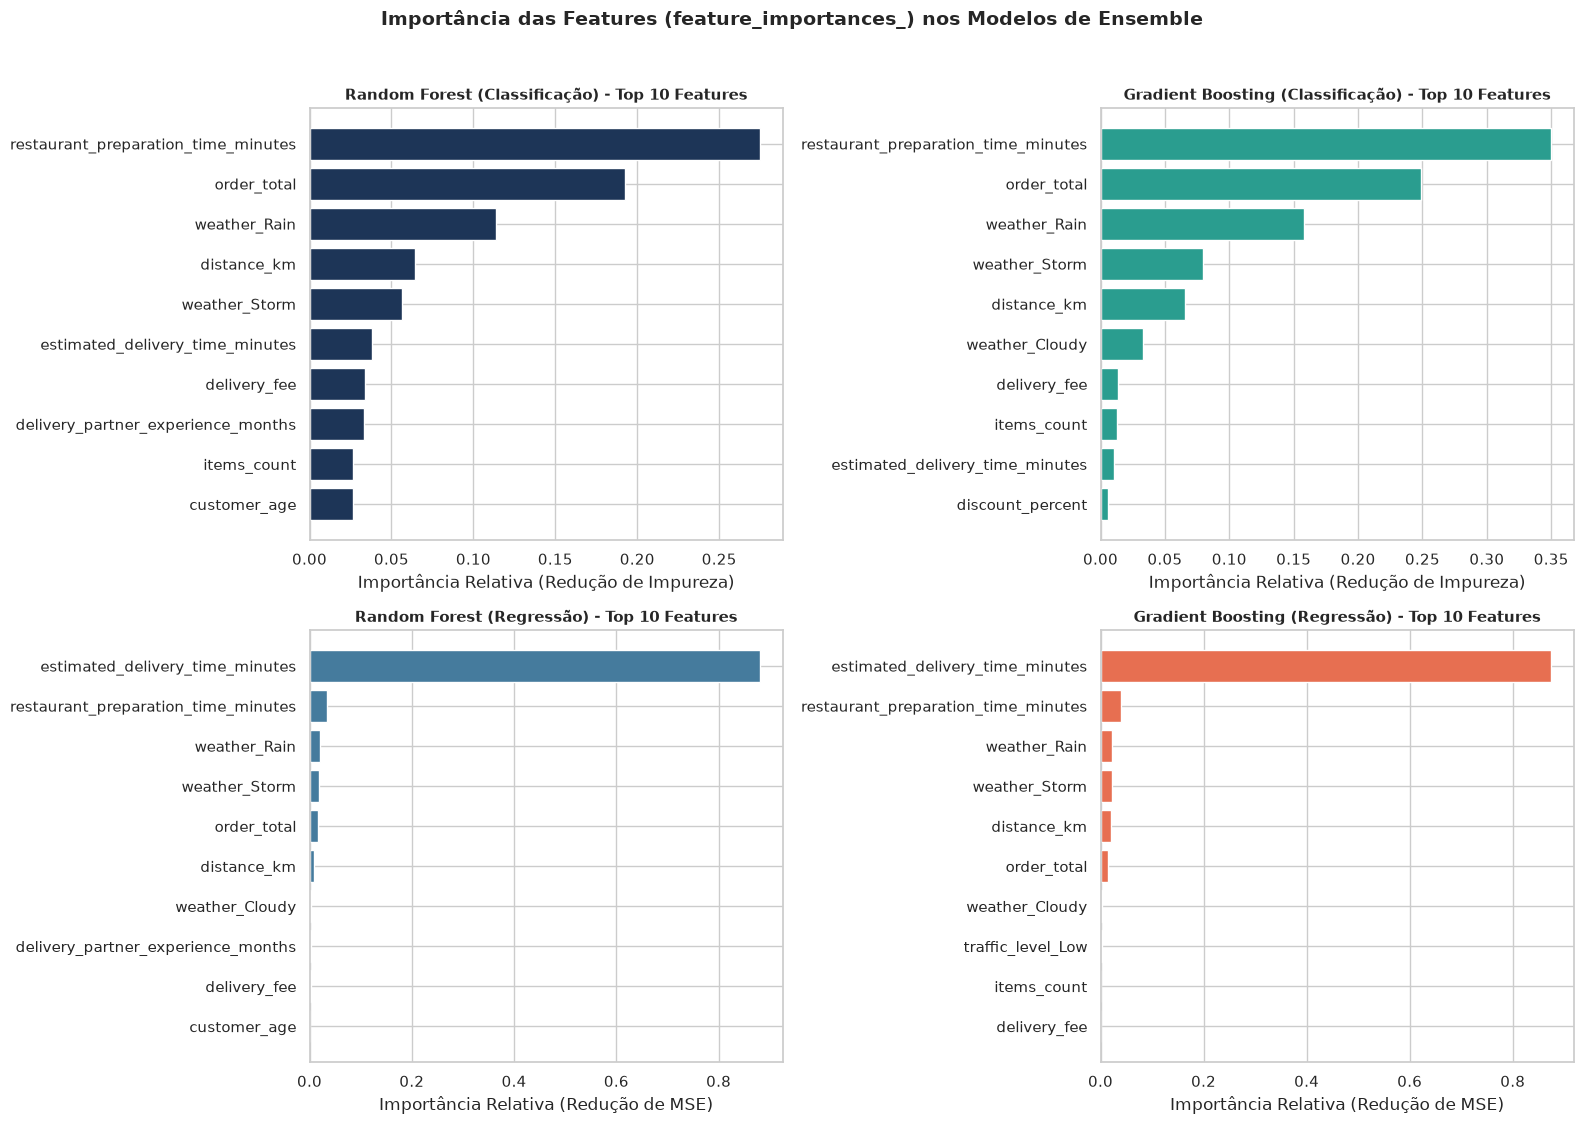

In [4]:
imp_df_clf = pd.DataFrame({
    "Feature": X_clf.columns,
    "RF_Classificacao": best_rf_clf.feature_importances_,
    "GB_Classificacao": best_gb_clf.feature_importances_
}).sort_values(by="RF_Classificacao", ascending=False).reset_index(drop=True)

imp_df_reg = pd.DataFrame({
    "Feature": X_reg.columns,
    "RF_Regressao": best_rf_reg.feature_importances_,
    "GB_Regressao": best_gb_reg.feature_importances_
}).sort_values(by="RF_Regressao", ascending=False).reset_index(drop=True)

imp_df_clf.to_csv("../reports/tables/ensemble_feature_importances_clf.csv", index=False)
imp_df_reg.to_csv("../reports/tables/ensemble_feature_importances_reg.csv", index=False)

print("=== TOP 10 FEATURES MAIS IMPORTANTES NA CLASSIFICAÇÃO (RANDOM FOREST vs. GRADIENT BOOSTING) ===")
display(imp_df_clf.head(10).round(4))

print("\n=== TOP 10 FEATURES MAIS IMPORTANTES NA REGRESSÃO (RANDOM FOREST vs. GRADIENT BOOSTING) ===")
display(imp_df_reg.head(10).round(4))

# Painel Visual 2x2: Feature Importances (RF e GB para Classificação e Regressão)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

top_rf_c = imp_df_clf.sort_values(by="RF_Classificacao", ascending=True).tail(10)
axes[0, 0].barh(top_rf_c["Feature"], top_rf_c["RF_Classificacao"], color="#1d3557")
axes[0, 0].set_title("Random Forest (Classificação) - Top 10 Features", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Importância Relativa (Redução de Impureza)")

top_gb_c = imp_df_clf.sort_values(by="GB_Classificacao", ascending=True).tail(10)
axes[0, 1].barh(top_gb_c["Feature"], top_gb_c["GB_Classificacao"], color="#2a9d8f")
axes[0, 1].set_title("Gradient Boosting (Classificação) - Top 10 Features", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Importância Relativa (Redução de Impureza)")

top_rf_r = imp_df_reg.sort_values(by="RF_Regressao", ascending=True).tail(10)
axes[1, 0].barh(top_rf_r["Feature"], top_rf_r["RF_Regressao"], color="#457b9d")
axes[1, 0].set_title("Random Forest (Regressão) - Top 10 Features", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Importância Relativa (Redução de MSE)")

top_gb_r = imp_df_reg.sort_values(by="GB_Regressao", ascending=True).tail(10)
axes[1, 1].barh(top_gb_r["Feature"], top_gb_r["GB_Regressao"], color="#e76f51")
axes[1, 1].set_title("Gradient Boosting (Regressão) - Top 10 Features", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Importância Relativa (Redução de MSE)")

plt.suptitle("Importância das Features (feature_importances_) nos Modelos de Ensemble", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/ensemble_feature_importances.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Comparação Visual de Desempenho e Eficiência Computacional dos Ensembles
Geramos também um gráfico comparativo direto entre **Árvore Isolada Sem Poda**, **Árvore Ajustada**, **Random Forest** e **Gradient Boosting** (evidenciando visualmente o ganho do Ensemble Learning sobre árvores individuais), além de medir o custo computacional de treinamento e inferência (30 repetições).

=== EFICIÊNCIA COMPUTACIONAL E COMPLEXIDADE DOS MODELOS DE ENSEMBLE ===


,Problema,Modelo,Num_Arvores,Nos_Totais,Profundidade_Max,Tempo_Treino_s,Pico_RAM_Treino_KB,Inferencia_Media_s (30 rep),Tempo_por_Amostra_ms,Vazao_amostras_s,Pico_RAM_Inferencia_KB,Tamanho_Disco_KB,Energia_Total_kWh,Emissao_CO2_g
0,Classificação,RandomForestClassifier,150,530144,16,3.9656,31622.87,0.20652,0.02102,47583.9,3671.92,41478.31,0.00001738,0.000796
1,Classificação,GradientBoostingClassifier,150,4522,4,16.3854,11982.58,0.03987,0.00406,246489.9,2999.54,363.87,0.00006844,0.003134
2,Regressão,RandomForestRegressor,150,1004300,16,5.1881,22923.00,0.21708,0.02209,45268.8,3267.29,70662.64,0.00002252,0.001031
3,Regressão,GradientBoostingRegressor,150,4454,4,15.8734,11982.49,0.03839,0.00391,255965.9,2998.46,358.88,0.00006630,0.003037


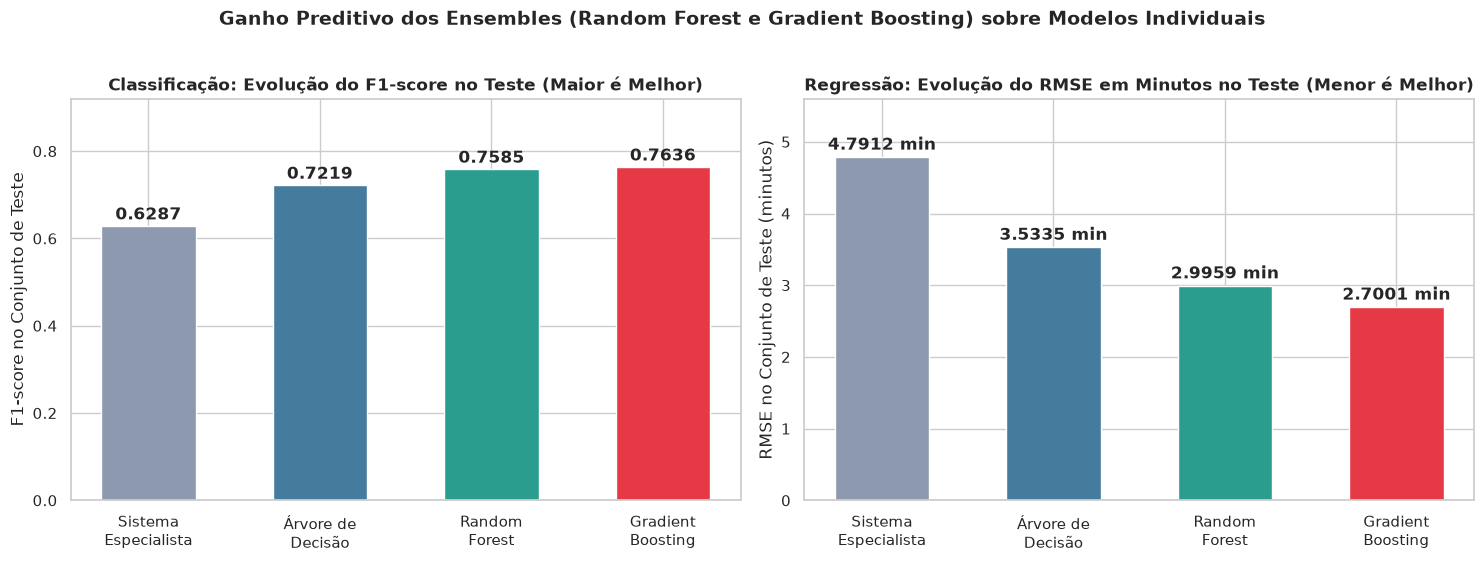

In [5]:
# Medição de Inferência (30 repetições) e Complexidade para os 4 Ensembles
prof_records = []
for prob, nome, mod, X_te, t_tr, ram_tr, pkl_path in [
    ("Classificação", "RandomForestClassifier", best_rf_clf, X_test_clf, t_rf_clf, ram_rf_clf, "../models/random_forest_clf.pkl"),
    ("Classificação", "GradientBoostingClassifier", best_gb_clf, X_test_clf, t_gb_clf, ram_gb_clf, "../models/gradient_boosting_clf.pkl"),
    ("Regressão", "RandomForestRegressor", best_rf_reg, X_test_reg, t_rf_reg, ram_rf_reg, "../models/random_forest_reg.pkl"),
    ("Regressão", "GradientBoostingRegressor", best_gb_reg, X_test_reg, t_gb_reg, ram_gb_reg, "../models/gradient_boosting_reg.pkl"),
]:
    comp = get_ensemble_complexity(mod)
    p_inf = medir_inferencia(mod.predict, X_te, n_rep=30)
    en = estimar_energia_co2(t_tr + p_inf["tempo_medio_s"])
    size_kb = os.path.getsize(pkl_path) / 1024.0
    prof_records.append({
        "Problema": prob,
        "Modelo": nome,
        "Num_Arvores": comp["n_arvores"],
        "Nos_Totais": comp["nos_totais"],
        "Profundidade_Max": comp["profundidade_max"],
        "Tempo_Treino_s": round(t_tr, 4),
        "Pico_RAM_Treino_KB": round(ram_tr / 1024.0, 2),
        "Inferencia_Media_s (30 rep)": round(p_inf["tempo_medio_s"], 5),
        "Tempo_por_Amostra_ms": round(p_inf["tempo_por_amostra_ms"], 5),
        "Vazao_amostras_s": round(p_inf["vazao_amostras_s"], 1),
        "Pico_RAM_Inferencia_KB": round(p_inf["pico_memoria_kb"], 2),
        "Tamanho_Disco_KB": round(size_kb, 2),
        "Energia_Total_kWh": f"{en['energia_kwh']:.8f}",
        "Emissao_CO2_g": f"{en['emissao_co2_g']:.6f}"
    })

df_prof_ens = pd.DataFrame(prof_records)
df_prof_ens.to_csv("../reports/tables/ensemble_profiling.csv", index=False)

print("=== EFICIÊNCIA COMPUTACIONAL E COMPLEXIDADE DOS MODELOS DE ENSEMBLE ===")
display(df_prof_ens)

# Gráfico comparativo: Evolução do Desempenho (Sistema Especialista -> Árvore Ajustada -> Random Forest -> Gradient Boosting)
dt_clf_saved = joblib.load("../models/decision_tree_clf.pkl")
dt_reg_saved = joblib.load("../models/decision_tree_reg.pkl")
exp_clf_saved = joblib.load("../models/expert_system_clf.pkl")
exp_reg_saved = joblib.load("../models/expert_system_reg.pkl")

m_exp_c = compute_classification_metrics(y_test_clf, exp_clf_saved.predict(X_test_clf))
m_dt_c = compute_classification_metrics(y_test_clf, dt_clf_saved.predict(X_test_clf))
m_rf_c = compute_classification_metrics(y_test_clf, best_rf_clf.predict(X_test_clf))
m_gb_c = compute_classification_metrics(y_test_clf, best_gb_clf.predict(X_test_clf))

m_exp_r = compute_regression_metrics(y_test_reg, exp_reg_saved.predict(X_test_reg))
m_dt_r = compute_regression_metrics(y_test_reg, dt_reg_saved.predict(X_test_reg))
m_rf_r = compute_regression_metrics(y_test_reg, best_rf_reg.predict(X_test_reg))
m_gb_r = compute_regression_metrics(y_test_reg, best_gb_reg.predict(X_test_reg))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
nomes_mod = ["Sistema\nEspecialista", "Árvore de\nDecisão", "Random\nForest", "Gradient\nBoosting"]
cores_mod = ["#8d99ae", "#457b9d", "#2a9d8f", "#e63946"]

f1_vals = [m_exp_c["F1-score"], m_dt_c["F1-score"], m_rf_c["F1-score"], m_gb_c["F1-score"]]
bars1 = axes[0].bar(nomes_mod, f1_vals, color=cores_mod, width=0.55)
axes[0].set_title("Classificação: Evolução do F1-score no Teste (Maior é Melhor)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("F1-score no Conjunto de Teste")
axes[0].set_ylim(0, 0.92)
for b in bars1:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 0.015, f"{h:.4f}", ha="center", fontweight="bold")

rmse_vals = [m_exp_r["RMSE"], m_dt_r["RMSE"], m_rf_r["RMSE"], m_gb_r["RMSE"]]
bars2 = axes[1].bar(nomes_mod, rmse_vals, color=cores_mod, width=0.55)
axes[1].set_title("Regressão: Evolução do RMSE em Minutos no Teste (Menor é Melhor)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("RMSE no Conjunto de Teste (minutos)")
axes[1].set_ylim(0, 5.6)
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 0.1, f"{h:.4f} min", ha="center", fontweight="bold")

plt.suptitle("Ganho Preditivo dos Ensembles (Random Forest e Gradient Boosting) sobre Modelos Individuais", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/ensemble_vs_single_tree.png", dpi=300, bbox_inches="tight")
plt.show()
